# Turtle Breakout 08 — risk per trade from 1% to 100% on BTC

Pre-registration: `discussions/Turtle_Breakout/010_claude_tb08_preregistration.md`. Code: `src/data_engineering/modeling/turtle_sizing.py`.

TB 01 daily long-only turtle on the BTCUSDT perpetual; only the risk fraction changes: $u = f \cdot \mathrm{HWM} / (2\,\mathrm{ATR})$, $f = 1\%, 2\%, \dots, 100\%$.
**Primary sweep P:** cap 125× notional, sizing on the high-water mark. **Reported:** C3 (TB 01's 3× cap), EQ (sizing on current equity).
**Decision:** for each $f \ne 2\%$, the paired difference in mean daily log return vs 2%, 21-day block bootstrap, Holm over 99 at $\alpha = 0.05$.

Environment: `TB01_DATA_DIR` (default `BINANCE_UM_DIR\long`), `TB08_SYNTHETIC=1`.

In [1]:
import os, sys, json, subprocess, tempfile, warnings, platform
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 120)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'src' / 'data_engineering').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); load_dotenv(ROOT / '.env')
from data_engineering.modeling import turtle_breakout as tb, turtle_trade_features as tf, turtle_sizing as ts

SYNTHETIC = os.getenv('TB08_SYNTHETIC', '0') == '1'
P = tb.Params(); SP = ts.SParams()
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='tb08-')) / '08'; SP = ts.SParams(n_boot=500, n_kelly_boot=500)
    b = tb.synthetic_5m(2400, seed=11, trend=0.01, start='2020-01-01'); f = tb.synthetic_funding(b, 0.0001)
else:
    OUT = ROOT / 'notebooks' / 'Turtle_Breakout' / '08'
    base = Path(os.environ['BINANCE_UM_DIR']) if os.environ.get('BINANCE_UM_DIR') else Path(os.environ['DERIBIT_DATA_ROOT']).parent / 'Binance'
    DATA = Path(os.environ.get('TB01_DATA_DIR', str(base / 'long')))
    b, _ = tf.load_um(DATA / 'BTCUSDT_um_1m.parquet')
    f = tb.funding_events(pd.read_parquet(DATA / 'basis' / 'funding' / 'BTCUSDT_funding.parquet'))
OUT.mkdir(parents=True, exist_ok=True)
env = os.environ.copy(); env['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + env.get('PYTHONPATH', '')
chk = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-p', 'test_turtle_sizing.py'], cwd=str(ROOT), env=env, capture_output=True, text=True)
print(chk.stderr.strip().splitlines()[-1]); assert chk.returncode == 0
D = tb.prepare_asset('BTC', b, f, P)
START = b.index[0] + pd.Timedelta(days=30)
print('BTC', b.index[0], '->', b.index[-1], '| start', START)
print(json.dumps(ts.registration(SP), indent=1))

OK
BTC 2020-01-01 00:05:00+00:00 -> 2026-10-24 00:00:00+00:00 | start 2020-01-31 00:05:00+00:00
{
 "max_lev_primary": 125.0,
 "max_lev_c3": 3.0,
 "block_days": 21,
 "n_boot": 2000,
 "n_kelly_boot": 5000,
 "alpha": 0.05,
 "seed": 20261026,
 "status": "PREREGISTERED_TB010",
 "version": "TB08-0.1.0",
 "fracs": "0.01..1.00 step 0.01",
 "base_f": 0.02,
 "asset": "BTC",
 "sweeps": {
  "P": "cap 125x, HWM sizing (primary)",
  "C3": "cap 3x (TB 01)",
  "EQ": "cap 125x, current-equity sizing"
 },
 "decision": "per f: mean daily log-return difference vs 2%, 21-day block bootstrap, Holm over 99, alpha 0.05",
 "reported": [
  "CAGR, Sharpe, max DD, Calmar, ruin, worst trade as % of equity, mean/max leverage",
  "Sharpe differences (Holm)",
  "C3 and EQ sweeps",
  "Kelly curve and bootstrap of the optimal f",
  "equity curves for selected f"
 ]
}


## 1. Reproduction check: f = 2%, 3× cap = TB 01 single-asset BTC

In [2]:
E, T, st = ts.run_f(D, P, 0.02, START, 3.0)
m = tb.metrics(E, T); print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in m.items()})
if not SYNTHETIC:
    ref = pd.read_csv(ROOT / 'notebooks' / 'Turtle_Breakout' / '01' / '01_single_asset.csv')
    display(ref[ref.iloc[:, 0] == 'BTC'])

{'start': '2020-01-31', 'end': '2026-10-24', 'years': 6.7296, 'final_equity': 217794.0601, 'total_return': 1.1779, 'cagr': 0.1226, 'sharpe': 0.9957, 'max_dd': -0.2081, 'trades': 54, 'win_rate': 0.3889, 'profit_factor': 2.4242, 'avg_hold_days': 18.255, 'fees': 3209.6696, 'funding': 24315.4641}


,Unnamed: 0,start,end,years,final_equity,total_return,cagr,sharpe,max_dd,trades,win_rate,profit_factor,avg_hold_days,fees,funding,twin_share
0,BTC,2020-01-31,2026-10-24,6.729637,217794.06014,1.177941,0.122619,0.995742,-0.208081,54,0.388889,2.424231,18.255015,3209.669585,24315.464099,0.239


## 2. The three sweeps

In [3]:
TAB, CUR = {}, {}
for name, cap, sb in (('P', SP.max_lev_primary, 'hwm'), ('C3', SP.max_lev_c3, 'hwm'), ('EQ', SP.max_lev_primary, 'equity')):
    TAB[name], CUR[name] = ts.sweep(D, P, START, cap, sb)
    print(name, 'done')
cols = ['f', 'cagr', 'log_growth_per_year', 'sharpe', 'max_dd', 'calmar', 'ruined', 'worst_trade_pct_equity', 'mean_gross_lev', 'max_gross_lev', 'capped_entries', 'final_equity']
sel = [0.01, 0.02, 0.03, 0.05, 0.075, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.75, 1.0]
for name in TAB:
    print(name); display(TAB[name][TAB[name].f.round(3).isin([round(x, 3) for x in sel])][cols].round(3))

P done
C3 done
EQ done
P


,f,cagr,log_growth_per_year,sharpe,max_dd,calmar,ruined,worst_trade_pct_equity,mean_gross_lev,max_gross_lev,capped_entries,final_equity
0,0.01,0.060,0.058,0.970,-0.108,0.552,False,-0.011,0.070,0.348,0,147914.769
1,0.02,0.123,0.116,0.996,-0.208,0.589,False,-0.025,0.141,0.699,0,217794.060
2,0.03,0.188,0.172,1.017,-0.300,0.625,False,-0.040,0.213,1.054,0,318386.461
4,0.05,0.325,0.281,1.048,-0.468,0.694,False,-0.081,0.362,2.292,0,663700.381
9,0.10,0.709,0.536,1.065,-0.826,0.858,False,-0.279,0.804,13.027,0,3681658.209
14,0.15,-1.000,-2.053,0.429,-1.000,-1.000,True,-1.283,1.204,37.328,0,0.100
19,0.20,-1.000,-2.053,0.031,-1.000,-1.000,True,-2.209,1.439,77.687,0,0.100
24,0.25,-1.000,-2.053,0.498,-1.000,-1.000,True,-1.817,1.633,63.376,0,0.100
29,0.30,-1.000,-2.053,0.502,-1.000,-1.000,True,-14.692,1.789,13.693,1,0.100
39,0.40,-1.000,-2.053,0.783,-1.000,-1.000,True,-2.274,2.735,71.724,0,0.100


C3


,f,cagr,log_growth_per_year,sharpe,max_dd,calmar,ruined,worst_trade_pct_equity,mean_gross_lev,max_gross_lev,capped_entries,final_equity
0,0.01,0.060,0.058,0.970,-0.108,0.552,False,-0.011,0.070,0.348,0,147914.769
1,0.02,0.123,0.116,0.996,-0.208,0.589,False,-0.025,0.141,0.699,0,217794.060
2,0.03,0.188,0.172,1.017,-0.300,0.625,False,-0.040,0.213,1.054,0,318386.461
4,0.05,0.325,0.281,1.048,-0.468,0.694,False,-0.081,0.362,2.292,0,663700.381
9,0.10,0.517,0.417,0.962,-0.781,0.663,False,-0.260,0.776,3.378,12,1653495.132
14,0.15,0.230,0.207,0.666,-0.952,0.241,False,-0.448,0.981,4.036,45,401656.752
19,0.20,0.217,0.197,0.665,-0.964,0.226,False,-0.470,1.006,4.356,47,375956.242
24,0.25,0.221,0.200,0.674,-0.970,0.228,False,-0.470,1.019,4.356,51,383778.948
29,0.30,0.222,0.200,0.676,-0.971,0.228,False,-0.470,1.022,4.356,53,384525.912
39,0.40,0.213,0.193,0.670,-0.971,0.220,False,-0.470,1.025,4.356,53,367231.275


EQ


,f,cagr,log_growth_per_year,sharpe,max_dd,calmar,ruined,worst_trade_pct_equity,mean_gross_lev,max_gross_lev,capped_entries,final_equity
0,0.01,0.057,0.056,0.966,-0.104,0.550,False,-0.011,0.067,0.313,0,145358.883
1,0.02,0.112,0.106,0.986,-0.192,0.583,False,-0.022,0.130,0.576,0,204192.225
2,0.03,0.164,0.152,1.002,-0.268,0.612,False,-0.033,0.189,0.801,0,278248.354
4,0.05,0.261,0.232,1.024,-0.394,0.663,False,-0.054,0.301,1.228,0,477232.467
9,0.10,0.459,0.378,1.044,-0.613,0.749,False,-0.109,0.548,2.437,0,1271414.734
14,0.15,0.590,0.464,1.038,-0.753,0.784,False,-0.163,0.764,3.642,0,2268963.913
19,0.20,0.655,0.504,1.021,-0.846,0.775,False,-0.218,0.961,5.027,0,2971069.318
24,0.25,0.658,0.505,0.998,-0.907,0.725,False,-0.272,1.143,6.513,0,3001700.334
29,0.30,0.604,0.473,0.971,-0.947,0.638,False,-0.326,1.316,8.112,0,2406509.084
39,0.40,0.364,0.311,0.915,-0.986,0.369,False,-0.435,1.640,11.701,0,809115.206


## 3. Decision: growth vs 2% (P sweep, Holm over 99)

In [4]:
CMP = ts.compare(CUR['P'], SP)
DEC = ts.decide(CMP, TAB['P'])
display(CMP[CMP.f.isin(sel)].round(4))
print(json.dumps(DEC, indent=1, default=float))
CMP_C3 = ts.compare(CUR['C3'], SP); CMP_EQ = ts.compare(CUR['EQ'], SP)
DEC_C3 = ts.decide(CMP_C3, TAB['C3']); DEC_EQ = ts.decide(CMP_EQ, TAB['EQ'])
print('C3:', {k: v for k, v in DEC_C3.items() if 'than' not in k}); print('EQ:', {k: v for k, v in DEC_EQ.items() if 'than' not in k})

,f,growth_diff,growth_lo95,growth_hi95,p_growth,sharpe_diff,sharpe_lo95,sharpe_hi95,p_sharpe,p_growth_holm,p_sharpe_holm,growth_result,sharpe_result
0,0.01,-0.0575,-0.1198,-0.0021,0.0544,-0.0254,-0.0597,0.0106,0.1626,1.0,1.0,NO_DIFFERENCE,NO_DIFFERENCE
1,0.03,0.0564,-0.0003,0.1202,0.0660,0.0210,-0.0136,0.0542,0.2355,1.0,1.0,NO_DIFFERENCE,NO_DIFFERENCE
3,0.05,0.1656,-0.0113,0.3598,0.0831,0.0522,-0.0501,0.1514,0.3167,1.0,1.0,NO_DIFFERENCE,NO_DIFFERENCE
8,0.10,0.4202,-0.1435,1.0773,0.1803,0.0693,-0.2164,0.3401,0.6283,1.0,1.0,NO_DIFFERENCE,NO_DIFFERENCE
13,0.15,-2.1686,-6.7473,0.4403,0.3058,-0.5667,-1.4056,0.2151,0.1711,1.0,1.0,NO_DIFFERENCE,NO_DIFFERENCE
18,0.20,-2.1686,-6.8784,0.4578,0.3112,-0.9651,-1.8814,0.1965,0.0708,1.0,1.0,NO_DIFFERENCE,NO_DIFFERENCE
23,0.25,-2.1686,-7.3289,0.6646,0.3554,-0.4978,-1.3748,0.4112,0.2804,1.0,1.0,NO_DIFFERENCE,NO_DIFFERENCE
28,0.30,-2.1686,-7.1868,0.7001,0.3077,-0.4942,-1.3879,0.4218,0.2871,1.0,1.0,NO_DIFFERENCE,NO_DIFFERENCE
38,0.40,-2.1686,-7.9614,1.1129,0.4038,-0.2129,-1.0598,0.6618,0.6276,1.0,1.0,NO_DIFFERENCE,NO_DIFFERENCE
48,0.50,-2.1686,-7.9661,1.4115,0.4045,-0.1503,-1.1470,0.7366,0.7515,1.0,1.0,NO_DIFFERENCE,NO_DIFFERENCE


{
 "higher_growth_than_2pct": [],
 "lower_growth_than_2pct": [],
 "n_higher": 0,
 "n_lower": 0,
 "n_no_difference": 99,
 "in_sample_best_f": 0.12,
 "in_sample_best_cagr": 0.8780335726378055,
 "in_sample_best_max_dd": -0.9549975997971466,
 "first_ruin_f": 0.13,
 "verdict": "2PCT_NOT_BEATEN"
}
C3: {'n_higher': 0, 'n_lower': 0, 'n_no_difference': 99, 'in_sample_best_f': 0.11, 'in_sample_best_cagr': 0.5352710906714031, 'in_sample_best_max_dd': -0.80820254443538, 'first_ruin_f': None, 'verdict': '2PCT_NOT_BEATEN'}
EQ: {'n_higher': 0, 'n_lower': 0, 'n_no_difference': 99, 'in_sample_best_f': 0.23, 'in_sample_best_cagr': 0.6639297853597623, 'in_sample_best_max_dd': -0.885429022311792, 'first_ruin_f': 0.8, 'verdict': '2PCT_NOT_BEATEN'}


## 4. Kelly: growth-optimal f on the trades, and how uncertain it is (reported)

In [5]:
E2, T2, _ = ts.run_f(D, P, 0.02, START, SP.max_lev_primary)
k = tb.period_id(pd.DatetimeIndex(T2.entry_time), 'day') - D.pid0
R = (T2.ret_notional / (P.stop_atr * D.atr[k] / T2.entry_px)).to_numpy()
R = R[T2.reason.to_numpy() != 'end']
KC = ts.kelly_curve(R); KB = ts.kelly_boot(R, SP)
KELLY = {'trades': int(len(R)), 'mean_R': float(R.mean()), 'win_rate': float((R > 0).mean()), 'worst_R': float(R.min()),
         'kelly_f': float(KC.idxmax()), 'half_kelly_f': float(KC.idxmax() / 2),
         'boot_q05': float(np.quantile(KB, .05)), 'boot_median': float(np.median(KB)), 'boot_q95': float(np.quantile(KB, .95)),
         'boot_share_f_le_2pct': float((KB <= 0.02).mean())}
print(json.dumps(KELLY, indent=1))

{
 "trades": 54,
 "mean_R": 0.7270392083483679,
 "win_rate": 0.3888888888888889,
 "worst_R": -1.088006950233927,
 "kelly_f": 0.23,
 "half_kelly_f": 0.115,
 "boot_q05": 0.06,
 "boot_median": 0.22,
 "boot_q95": 0.4,
 "boot_share_f_le_2pct": 0.0236
}


## 5. Figures

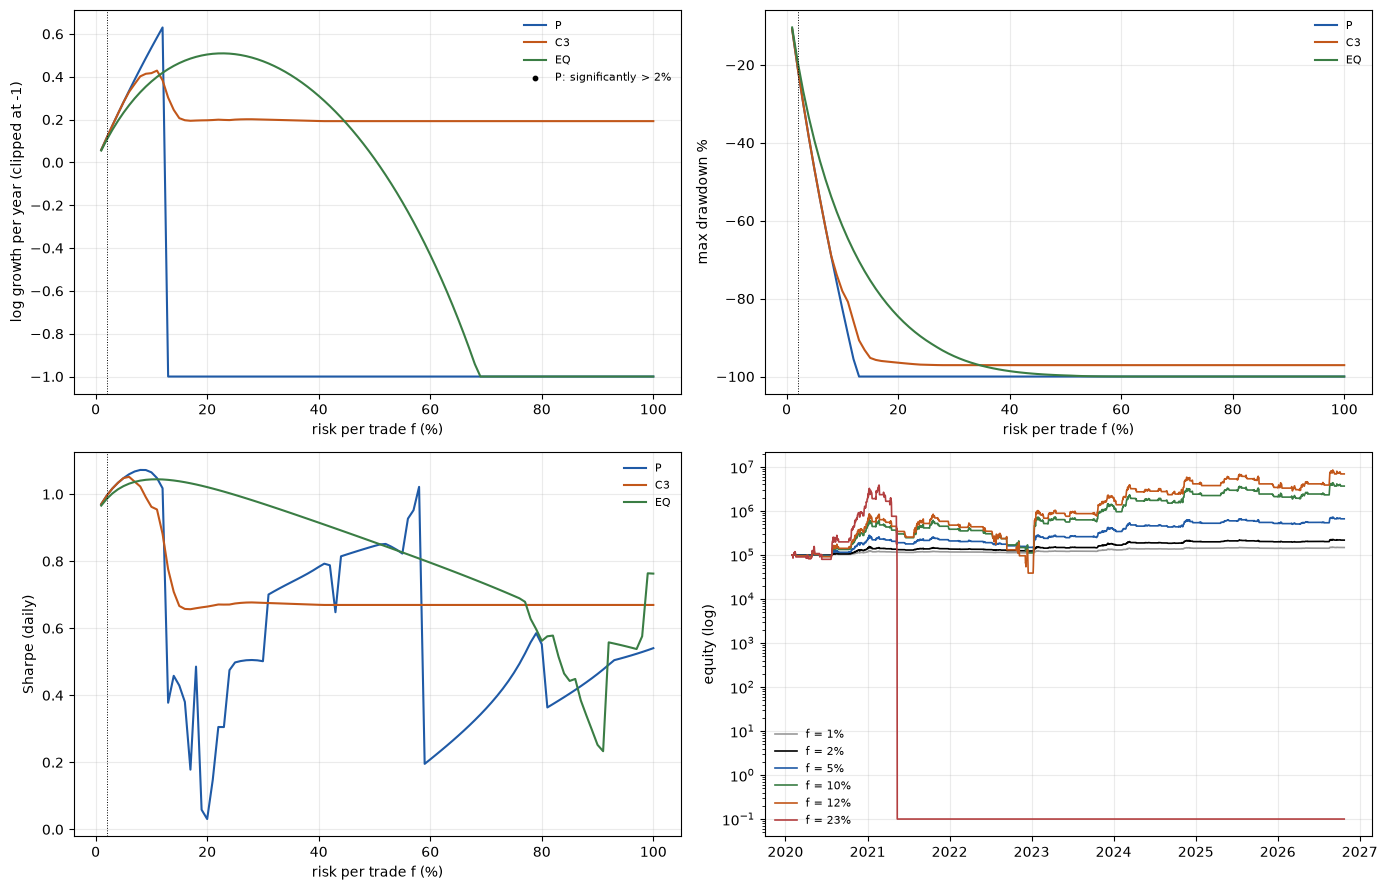

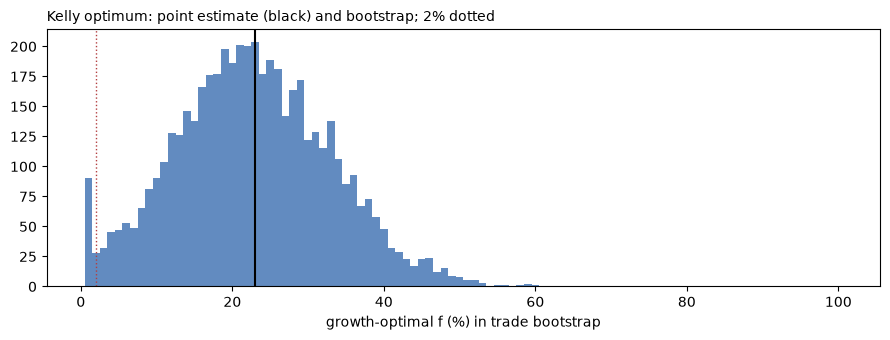

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for name, col in (('P', '#1f5aa6'), ('C3', '#c2571a'), ('EQ', '#3a7d44')):
    t = TAB[name]
    axes[0, 0].plot(t.f * 100, t.log_growth_per_year.clip(lower=-1), color=col, label=name)
    axes[0, 1].plot(t.f * 100, t.max_dd * 100, color=col, label=name)
    axes[1, 0].plot(t.f * 100, t.sharpe, color=col, label=name)
axes[0, 0].set_ylabel('log growth per year (clipped at -1)'); axes[0, 1].set_ylabel('max drawdown %'); axes[1, 0].set_ylabel('Sharpe (daily)')
c = CMP
axes[0, 0].scatter(c.f[c.growth_result == 'HIGHER_GROWTH'] * 100, [TAB['P'].set_index('f').log_growth_per_year[x] for x in c.f[c.growth_result == 'HIGHER_GROWTH']], color='k', s=10, zorder=4, label='P: significantly > 2%')
for a in axes.ravel()[:3]:
    a.axvline(2, color='k', lw=0.7, ls=':'); a.set_xlabel('risk per trade f (%)'); a.grid(alpha=0.25); a.legend(frameon=False, fontsize=8)
for x, col in zip((0.01, 0.02, 0.05, 0.1, KELLY['half_kelly_f'], KELLY['kelly_f']), ('0.6', 'k', '#1f5aa6', '#3a7d44', '#c2571a', '#b33f40')):
    x = round(min(max(x, 0.01), 1.0), 2)
    axes[1, 1].plot(CUR['P'].index, CUR['P'][x], color=col, lw=1.2, label=f'f = {x:.0%}')
axes[1, 1].set_yscale('log'); axes[1, 1].set_ylabel('equity (log)'); axes[1, 1].legend(frameon=False, fontsize=8); axes[1, 1].grid(alpha=0.25)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(KB * 100, bins=np.arange(0.5, 101.5, 1), color='#1f5aa6', alpha=0.7); ax.axvline(KELLY['kelly_f'] * 100, color='k', lw=1.5)
ax.axvline(2, color='#b33f40', lw=1, ls=':'); ax.set_xlabel('growth-optimal f (%) in trade bootstrap'); ax.set_title('Kelly optimum: point estimate (black) and bootstrap; 2% dotted', loc='left', fontsize=10)
plt.tight_layout(); plt.show()

## 6. Save

In [7]:
for name in TAB:
    TAB[name].to_csv(OUT / f'08_sweep_{name}.csv', index=False)
CMP.to_csv(OUT / '08_compare_P.csv', index=False); CMP_C3.to_csv(OUT / '08_compare_C3.csv', index=False); CMP_EQ.to_csv(OUT / '08_compare_EQ.csv', index=False)
CUR['P'][[x for x in (0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0)]].to_csv(OUT / '08_curves_P_selected.csv')
(OUT / '08_decision.json').write_text(json.dumps({'decision': DEC, 'C3': DEC_C3, 'EQ': DEC_EQ, 'kelly': KELLY,
    'reproduction_2pct_cap3': m, 'registration': ts.registration(SP), 'synthetic': SYNTHETIC}, indent=1, default=str))
git = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=str(ROOT), capture_output=True, text=True).stdout.strip()
(OUT / '08_manifest.json').write_text(json.dumps({'version': ts.VERSION, 'tb01_version': tb.VERSION, 'git': git, 'python': platform.python_version(),
    'created_utc': pd.Timestamp.now('UTC').isoformat(), 'start': str(START), 'synthetic': SYNTHETIC}, indent=1))
print('saved to', OUT); print('VERDICT:', DEC['verdict'])

saved to D:\Projects\deribit_market_data\notebooks\Turtle_Breakout\08
VERDICT: 2PCT_NOT_BEATEN
